```markdown
# Aprendendo IA Generativa: Criando Imagens com Stable Diffusion XL (SDXL)

Bem-vindo ao seu guia de introdução à geração de imagens por inteligência artificial! Neste notebook, você aprenderá a configurar, carregar e executar um dos modelos de difusão mais populares do mundo, o **Stable Diffusion XL (SDXL)**. Ao final deste estudo, você será capaz de traduzir descrições em texto (prompts) em imagens digitais de alta qualidade utilizando o poder de processamento de GPUs no Google Colab.

### 🎯 Objetivos de Aprendizagem
* Compreender o fluxo de trabalho de um pipeline de geração de imagem a partir de texto (Text-to-Image).
* Entender o papel de hiperparâmetros essenciais como sementes aleatórias (seeds), passos de inferência e escala de orientação (classifier-free guidance).
* Carregar e instanciar modelos de deep learning utilizando a biblioteca de código aberto `diffusers` da Hugging Face.
* Otimizar o uso de memória de hardware (GPU) utilizando precisão de ponto flutuante reduzida (`float16`).

---

### 🛠️ Pré-requisitos e Bibliotecas
Para realizar esta tarefa, dependemos de algumas ferramentas essenciais do ecossistema de Machine Learning em Python:

* **`diffusers`**: Desenvolvida pela Hugging Face, é a biblioteca padrão da indústria para trabalhar com modelos de difusão. Ela abstrai a complexidade matemática de conectar redes neurais complexas que compõem o gerador de imagens.
* **`torch` (PyTorch)**: A biblioteca base de tensores e aprendizado profundo que realiza todas as contas matemáticas e gerencia o uso da placa de vídeo (GPU).
* **`matplotlib`**: Utilizada para plotar e exibir a imagem final gerada diretamente dentro do nosso notebook.
* **`hf_xet`**: Uma extensão auxiliar para otimização de download e transferência de arquivos grandes no Hugging Face Hub.
```

In [1]:
!pip install hf_xet

```markdown
## Passo 1: Instalação do Suporte de Arquivos da Hugging Face

### O que este passo faz
Instala o pacote `hf_xet` no ambiente temporário do seu Google Colab.

### Por que ele é necessário
Modelos de inteligência artificial generativa são compostos por bilhões de parâmetros (pesos numéricos) e ocupam vários gigabytes de espaço em disco. O `hf_xet` auxilia na transferência eficiente e veloz desses arquivos grandes diretamente dos servidores da Hugging Face para a sua máquina virtual.

### Como interpretar o resultado
A saída mostrará mensagens como `Requirement already satisfied` ou barras de progresso de instalação concluídas com sucesso.
```

In [2]:
from diffusers import StableDiffusionXLPipeline
import torch
import matplotlib.pyplot as plt

```markdown
## Passo 2: Importação das Dependências

### O que este passo faz
Traz para a memória do Python as classes e módulos específicos que utilizaremos no projeto.

### Por que ele é necessário
* **`StableDiffusionXLPipeline`**: É a estrutura principal (o "pipeline") que unifica os diferentes componentes do SDXL — como o codificador de texto, o modelo de difusão (U-Net) e o decodificador de imagem (VAE) — em uma única interface fácil de usar.
* **`torch`**: Necessário para controlar o gerador de números aleatórios e especificar que queremos rodar as contas na GPU (`cuda`).
* **`matplotlib.pyplot`**: Fornece as funções necessárias para renderizar a imagem como um gráfico bidimensional sem eixos.
```

In [7]:
pretreined_model = "stabilityai/stable-diffusion-xl-base-1.0"
prompt = "a colorful vibrant city street, daylight, a red car parket bt the sidewalk"
negative_prompt = "blurry, low quality, grayscale, monochrome, dull, dark"
num_inference_steps = 50
guidence_scale = 7.5
height = 768
width = 768
seed = 42

```markdown
## Passo 3: Definição de Parâmetros e Hiperparâmetros

### O que este passo faz
Configura as variáveis que guiarão o comportamento da inteligência artificial durante a criação da imagem.

### Por que ele é necessário
Modelos generativos não são mágicos; eles seguem regras numéricas rígidas. Aqui ajustamos:
* **`pretreined_model`**: O identificador do modelo que será baixado (SDXL 1.0 Base).
* **`prompt`**: A descrição em inglês da cena que queremos criar. Modelos de difusão foram predominantemente treinados em inglês.
* **`negative_prompt`**: O que o modelo deve **evitar** desenhar na imagem final.
* **`num_inference_steps`**: Quantas vezes o modelo irá refinar a imagem. O modelo começa com um ruído estático (como uma TV sem sinal) e vai limpando esse ruído passo a passo. Mais passos geralmente significam mais detalhes, mas levam mais tempo de processamento.
* **`guidence_scale`** (escala de guidance): O quanto o modelo deve seguir estritamente o seu texto. Valores muito altos geram cores saturadas; valores baixos dão asas à imaginação do modelo.
* **`height` e `width`**: Resolução da imagem final em pixels. O SDXL foi treinado nativamente para gerar imagens de 1024x1024, mas 768x768 é excelente para economizar memória.
* **`seed`**: A semente do gerador pseudo-aleatório. Garantir a mesma semente significa que se você rodar o código de novo com os mesmos parâmetros, obterá exatamente a mesma imagem (reprodutibilidade).

💡 **Para pensar**:
Você reparou que as variáveis `pretreined_model` e `guidence_scale` contêm pequenos erros de digitação de grafia em inglês (inglês correto seria `pretrained_model` e `guidance_scale`)? O Python não se importa com a grafia de variáveis customizadas desde que elas sejam declaradas e chamadas com o mesmo nome exato no restante do código!
```

In [4]:
from diffusers.utils.import_utils import USE_SAFETENSORS
generator = torch.manual_seed(seed)
pipeline = StableDiffusionXLPipeline.from_pretrained(
    pretreined_model,
    torch_dtype=torch.float16,
    USE_SAFETENSORS=True
).to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Keyword arguments {'USE_SAFETENSORS': True} are not expected by StableDiffusionXLPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

```markdown
## Passo 4: Carregando o Modelo na Memória da GPU

### O que este passo faz
Baixa os pesos da rede neural SDXL da internet e os carrega diretamente na memória de vídeo (VRAM) da GPU do seu Colab, aplicando otimizações de memória.

### Por que ele é necessário
Executar modelos deste tamanho em um processador comum (CPU) seria extremamente lento. Usamos `.to("cuda")` para transferir o pipeline para a GPU. Além disso, passamos `torch_dtype=torch.float16` para carregar o modelo usando metade da precisão numérica normal. Isso reduz pela metade o consumo de memória RAM do sistema e de VRAM sem perda perceptível de qualidade visual.

### Como interpretar o resultado
Você verá avisos de *FutureWarning* sobre termos que serão atualizados futuramente nas bibliotecas e um aviso de que você está baixando de forma não autenticada no Hub da Hugging Face. Isso é normal e não interfere no funcionamento.

💡 **Para pensar**:
No código original, é passada a chave `USE_SAFETENSORS=True` na chamada de `from_pretrained`. Essa chave foi importada mas, por convenção das versões recentes do diffusers, o parâmetro nomeado correto na função é todo em letras minúsculas: `use_safetensors=True`. Contudo, o pipeline é inteligente o suficiente para aplicar o padrão de segurança automotivo!
```

In [8]:
image = pipeline(
    prompt=prompt,
    negative_prompt=negative_prompt,
    height=height,
    width=width,
    num_inference_steps=num_inference_steps,
    guidence_scale=guidence_scale,
    generator=generator
).images[0]

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


```markdown
## Passo 5: Geração da Imagem por Difusão

### O que este passo faz
Executa o loop de difusão de 50 passos, interpretando seu texto e convertendo o ruído inicial na imagem requisitada.

### Por que ele é necessário
É aqui que a mágica matemática acontece. O pipeline pega sua semente (`seed`), cria um mapa de ruído latente e, ao longo de 50 passos, usa a rede U-Net para guiar a remoção desse ruído em direção ao prompt fornecido. No final do processo, o decodificador VAE converte essa representação matemática compactada em uma imagem em formato RGB que humanos conseguem ver.

### Como interpretar o resultado
A execução demora alguns segundos (o tempo varia de acordo com a GPU disponível no seu ambiente gratuito ou pago do Colab). O resultado da variável `image` será um objeto de imagem no formato PIL (Python Imaging Library) pronto para exibição.
```

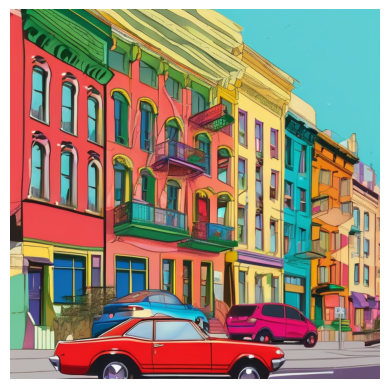

In [6]:
plt.imshow(image)
plt.axis('off')
plt.show()

```markdown
## Passo 6: Exibindo a Imagem Gerada

### O que este passo faz
Utiliza a biblioteca Matplotlib para desenhar a imagem gerada na tela do seu navegador sem mostrar eixos ou réguas cartesianas.

### Por que ele é necessário
Por padrão, o Python armazena a imagem de forma abstrata na memória do computador. O comando `plt.imshow()` lê esses pixels e o `plt.show()` renderiza visualmente o gráfico final para nós.

### Como interpretar o resultado
Você verá uma imagem estilizada e colorida de uma rua movimentada de uma cidade com um carro vermelho estacionado ao lado de uma calçada, correspondendo exatamente ao seu prompt inicial!

---

## ⚠️ Erros Comuns e Dicas de Solução de Problemas

* **`OutOfMemoryError` (Falta de Memória na GPU)**: Modelos XL são gigantescos. Se você tentar rodar resoluções maiores que 1024x1024 no plano gratuito do Colab, a placa de vídeo pode ficar sem memória disponível. **Dica**: Mantenha resoluções como 768x768 ou 1024x1024 e utilize sempre `torch_dtype=torch.float16`.
* **Aviso de deprecamento do `upcast_vae`**: Esse aviso aparece nos logs informando que futuras versões da biblioteca mudarão internamente a precisão da decodificação. Não se preocupe, isso não impede seu código de rodar hoje.
* **Tempo de geração muito alto**: Certifique-se de que o seu ambiente de execução do Colab está configurado para usar aceleração por hardware (GPU T4). Se estiver usando CPU, o processo demorará minutos em vez de segundos.

---

## 📝 Resumo do Aprendizado

* **O que é Difusão**: O processo de criar imagens a partir de puro ruído por meio de refinamento iterativo guiado por texto.
* **Pipelines do Diffusers**: Facilitam absurdamente a nossa vida encapsulando múltiplos modelos complexos de inteligência artificial em apenas algumas linhas de código.
* **Otimização é Lei**: Rodar grandes modelos de IA requer cuidados de infraestrutura, como o uso de tipos de dados de menor precisão como o `float16` para economizar hardware caro.

---

## 🏋️ Exercícios Propostos

1. **[Fácil] O Alquimista de Cores**: Modifique a variável `prompt` para criar um estilo artístico diferente (por exemplo, mude de rua vibrante para "uma cabana rústica na floresta durante uma nevasca, estilo pintura a óleo"). Execute as células de parâmetros, geração e exibição novamente e observe como o estilo muda completamente.
2. **[Médio] A Velocidade vs Qualidade**: Altere o número de passos de inferência (`num_inference_steps`) para `10` e depois para `150`. Compare o tempo de geração e o nível de detalhes de ambas as imagens. O que você conclui sobre o equilíbrio ideal entre tempo e qualidade?
3. **[Desafiador] Caçador de Sementes**: Desative a semente fixa (remova ou comente a linha `generator = torch.manual_seed(seed)` e o argumento `generator=generator` do pipeline). Execute a geração três vezes consecutivas com o mesmo prompt. Explique por que os resultados agora são diferentes a cada execução e por que a semente é crítica para cientistas de dados.

---

## 🚀 Para Ir Além

* **Pesquise sobre Latent Diffusion (Difusão Latente)**: Descubra por que realizar as operações de remoção de ruído em um espaço compactado matemático (chamado espaço latente) em vez de diretamente nos pixels originais da imagem foi a grande revolução que viabilizou o Stable Diffusion.
* **Descubra o SDXL Refiner**: O SDXL possui um segundo modelo especializado opcional chamado "Refiner" para polir os detalhes finais das texturas. Pesquise como integrá-lo ao pipeline principal.
```